# Find your match: Columbia Speed Dating data

Answer the same sign-up survey the speed-dating participants filled in, and the trained GraphSAGE model will:
1. score you against every opposite-gender participant (the experiment only had male-female dates),
2. list your closest matches,
3. show where you land on the real match network and in the model's embedding space.

**How it works for a new user:** you're added to the graph as a new node with no matches yet.
GraphSAGE builds your embedding from your survey answers alone (it was trained with some people's
matches hidden, so it handles this case). The decoder then scores you against everyone else.

**Expect modest accuracy.** On people it has never seen, the model reaches about 0.62-0.64 test AUC.
Most of what makes two people match on a speed date (attraction, chemistry) isn't in the survey.

In [1]:
%matplotlib inline
from pathlib import Path

import pandas as pd
from IPython.display import display

from new_user import SELF_RATING_NAMES, find_matches, plot_new_user
from predict import load
from speed_dating import FIELDS, FREQUENCY, GENDERS, GOALS, HOBBIES, PREFERENCE_NAMES, RACES

if not Path("match_sage.pt").exists():
    raise FileNotFoundError("Run `python sage_model.py` first to train and save the model.")

ctx = load()
pd.set_option("display.max_colwidth", 70)
print(f"Loaded model and {len(ctx['people'])} participants. Match threshold: p >= {ctx['threshold']:.3f}")
print("Goals:     ", list(GOALS.values()))
print("Fields:    ", list(FIELDS.values()))
print("Races:     ", list(RACES.values()))
print("Frequency: ", list(FREQUENCY.values()))
print("Hobbies:   ", HOBBIES)

Loaded model and 551 participants. Match threshold: p >= 0.035
Goals:      ['fun night out', 'meet new people', 'get a date', 'serious relationship', 'to say I did it', 'other']
Fields:     ['law', 'math', 'social science / psychology', 'medical science / pharma / biotech', 'engineering', 'english / writing / journalism', 'history / religion / philosophy', 'business / econ / finance', 'education / academia', 'biology / chemistry / physics', 'social work', 'undergrad / undecided', 'political science / intl affairs', 'film', 'fine arts', 'languages', 'architecture', 'other']
Races:      ['black', 'white', 'latino', 'asian', 'native american', 'other']
Frequency:  ['several times a week', 'twice a week', 'once a week', 'twice a month', 'once a month', 'several times a year', 'almost never']
Hobbies:    ['sports', 'tvsports', 'exercise', 'dining', 'museums', 'art', 'hiking', 'gaming', 'clubbing', 'reading', 'tv', 'theater', 'movies', 'concerts', 'music', 'shopping', 'yoga']


## Option 1: describe yourself in code

Edit the profile below and run the cell. Hobbies, self-ratings and the importance scales are 1-10.
`looking_for` can use any numbers: they're turned into shares of the total, like the survey's
"distribute 100 points".

In [2]:
profile = {
    "gender": "female",              # female / male
    "age": 25,
    "field": "engineering",          # see Fields above
    "goal": "serious relationship",  # see Goals above
    "race": "white",                 # see Races above
    "date_frequency": "twice a month",  # how often you go on dates
    "go_out_frequency": "once a week",  # how often you go out (not on dates)
    "importance_same_race": 3,          # 1-10
    "importance_same_religion": 2,      # 1-10
    "expected_happiness": 6,            # how happy you expect to be with the people you meet (1-10)
    "hobbies": {
        "sports": 6, "tvsports": 2, "exercise": 7, "dining": 8, "museums": 8, "art": 7,
        "hiking": 9, "gaming": 3, "clubbing": 4, "reading": 9, "tv": 3, "theater": 7,
        "movies": 8, "concerts": 7, "music": 9, "shopping": 4, "yoga": 6,
    },
    "looking_for": {  # what matters to you in a partner
        "attractive": 20, "sincere": 20, "intelligent": 20, "fun": 20, "ambitious": 10, "shared interests": 10,
    },
    "self_rating": {  # how you rate yourself (1-10)
        "attractive": 7, "sincere": 8, "intelligent": 8, "fun": 7, "ambitious": 7,
    },
}
TOP_K = 10

top_matches, embeddings = find_matches(ctx, profile, top_k=TOP_K)
best = top_matches.iloc[0]
print(f"Closest match: participant {best['id']} with p(match) = {best['p_match']:.2f}")
display(top_matches)

Closest match: participant 422 with p(match) = 0.77


,id,p_match,predicted,age,goal,field,race,interest_corr,shared_passions
0,422,0.774,match,26.0,meet new people,business / econ / finance,white,0.76,"[dining, museums, hiking, movies]"
1,107,0.690,match,21.0,fun night out,history / religion / philosophy,white,0.73,"[hiking, music]"
2,448,0.653,match,22.0,fun night out,law,white,0.45,"[dining, museums, music]"
3,535,0.640,match,23.0,fun night out,biology / chemistry / physics,white,0.21,"[reading, movies, music]"
4,99,0.639,match,28.0,get a date,law,white,0.36,"[dining, museums, movies, music]"
5,404,0.635,match,23.0,meet new people,engineering,white,0.49,"[dining, museums, hiking, reading, movies, music]"
6,424,0.631,match,24.0,meet new people,engineering,asian,-0.27,[movies]
7,552,0.621,match,25.0,fun night out,other,white,0.69,"[dining, museums, reading, movies, music]"
8,335,0.616,match,24.0,fun night out,social science / psychology,white,0.48,"[reading, music]"
9,442,0.589,match,25.0,serious relationship,law,white,0.40,[]


- `p_match`: the model's predicted chance of a mutual "yes". About 16% of real dates matched,
  so anything well above 0.16 is a good sign.
- `predicted`: "match" if `p_match` is at or above the saved threshold. That threshold was tuned to
  catch most real matches (high recall), so it labels many people "match": rely on the ranking more than the label.
- `interest_corr`: how similarly you and they rate the 17 hobbies (-1 to 1).
- `shared_passions`: hobbies you both rated 8 or higher.

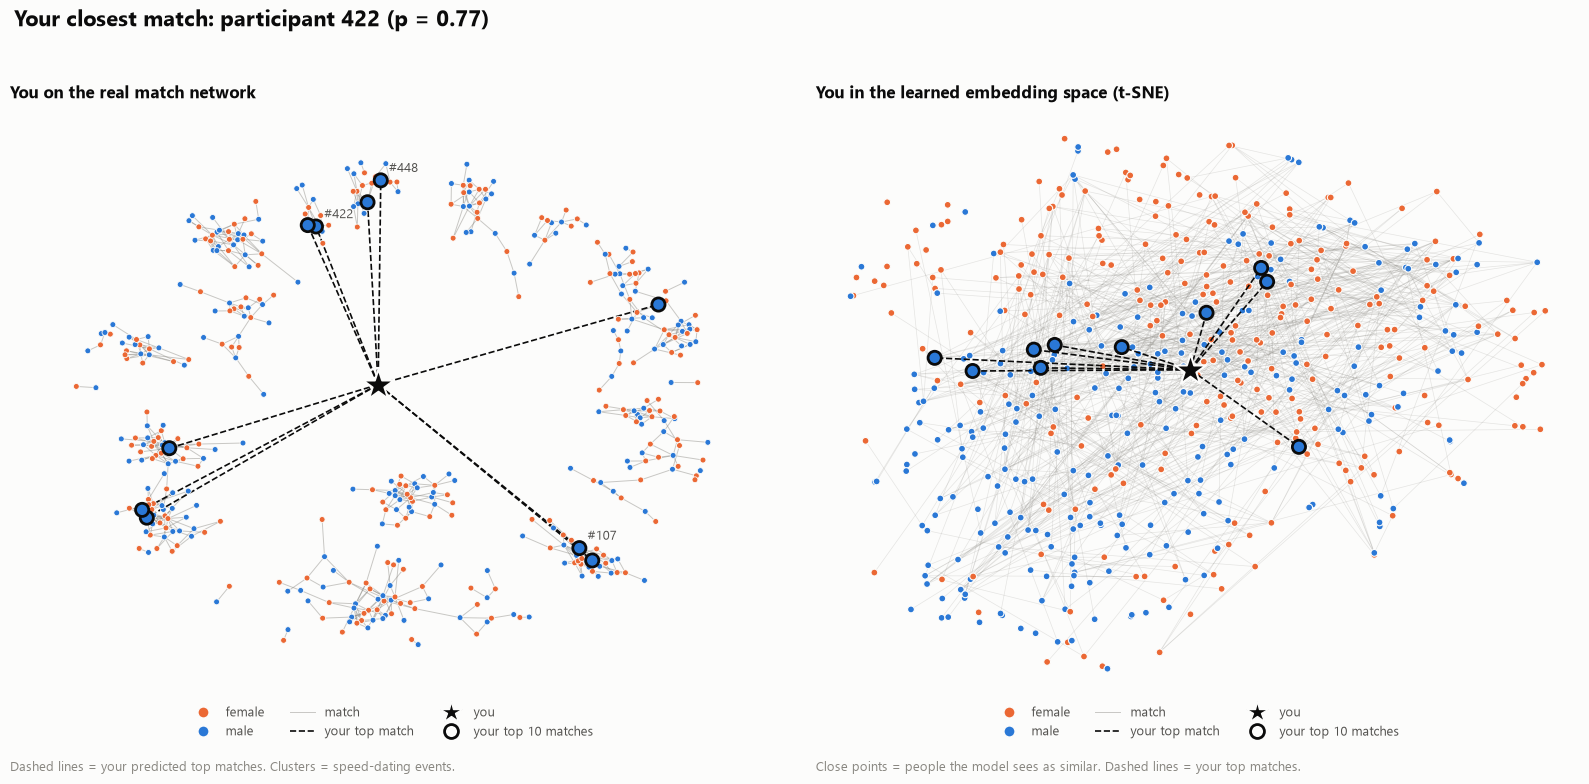

In [3]:
fig = plot_new_user(ctx, top_matches, embeddings)

## Option 2: interactive form

Fill in the survey and click **Find my matches**.

In [4]:
import ipywidgets as w
import matplotlib.pyplot as plt

style = {"description_width": "130px"}
wide = w.Layout(width="380px")


def slider(name, value, lo=1, hi=10):
    return w.IntSlider(value=value, min=lo, max=hi, description=name, style=style, layout=wide)


def dropdown(name, options, value=None):
    return w.Dropdown(options=options, value=value or options[0], description=name, style=style, layout=wide)


about = {
    "gender": dropdown("Gender", list(GENDERS.values())),
    "age": slider("Age", 25, 18, 60),
    "field": dropdown("Field of study", list(FIELDS.values()), "engineering"),
    "goal": dropdown("Goal", list(GOALS.values()), "serious relationship"),
    "race": dropdown("Race", list(RACES.values()), "white"),
    "date_frequency": dropdown("Go on dates", list(FREQUENCY.values()), "twice a month"),
    "go_out_frequency": dropdown("Go out", list(FREQUENCY.values()), "once a week"),
    "importance_same_race": slider("Same race matters", 3),
    "importance_same_religion": slider("Same religion matters", 2),
    "expected_happiness": slider("Expect to enjoy", 6),
}
hobbies = {h: slider(h, 5) for h in HOBBIES}
looking_for = {name: slider(name, 5) for name in PREFERENCE_NAMES}
self_rating = {name: slider(name, 7) for name in SELF_RATING_NAMES}
top_k = slider("Show top", 10, 1, 25)
button = w.Button(description="Find my matches", button_style="primary", icon="heart")
output = w.Output()


def on_click(_):
    output.clear_output()
    user = {key: widget.value for key, widget in about.items()}
    user["hobbies"] = {h: s.value for h, s in hobbies.items()}
    user["looking_for"] = {n: s.value for n, s in looking_for.items()}
    user["self_rating"] = {n: s.value for n, s in self_rating.items()}
    with output:
        try:
            found, z = find_matches(ctx, user, top_k=top_k.value)
        except ValueError as err:
            print(f"Please fix your profile: {err}")
            return
        print(f"Closest match: participant {found.iloc[0]['id']} with p(match) = {found.iloc[0]['p_match']:.2f}")
        display(found)
        plot_new_user(ctx, found, z)
        plt.show()


def section(title, widgets):
    return w.VBox([w.HTML(f"<b>{title}</b>"), *widgets])


button.on_click(on_click)
hobby_list = list(hobbies.values())
display(w.VBox([
    w.HBox([section("About you", about.values()),
            w.VBox([section("What matters in a partner (1-10)", looking_for.values()),
                    section("How you rate yourself (1-10)", self_rating.values())])]),
    section("How much you enjoy these (1-10)", [w.HBox([w.VBox(hobby_list[i::3]) for i in range(3)])]),
    w.HBox([top_k, button]),
    output,
]))